# Demo: du bao doanh thu va ho tro toi uu ton kho

Notebook thuc hien EDA, kiem tra/lap feature, phan tich kinh doanh, so sanh baseline va mot so mo hinh regression cho bai toan du bao theo ngay.

> **Luu y quan trong:** lich su ban hang la Online Retail II (GBP), duoc gan nhan gia lap cho 59 san pham HairCare. Ket qua chi danh cho demo hoc thuat, khong phan anh doanh thu hay nhu cau HairCare that. Ton kho, lead time, chu ky nhap va muc ton an toan trong phan khuyen nghi la gia dinh co the chinh sua.

**Taxonomy demo:** 6 nhom `shampoo`, `hairmask`, `treatment`, `dry shampoo`, `conditioner`, `hairstyling`; cac nhan `oil` va `serum` duoc gop vao `treatment`.

**Muc tieu:** du bao `revenue_gbp` de theo doi doanh thu va `quantity_sold` de tinh luong dat hang. Khong the suy ra so luong nhap tu doanh thu neu khong co gia ban tuong lai; vi vay khuyen nghi ton kho duoc tinh tu du bao quantity. Gia catalog USD khong duoc tron vao doanh thu GBP.

## 1. Cau hinh va nap du lieu

Notebook tu tim `processed/haircare_demo_daily_sales.csv` tu thu muc hien tai hoac cac thu muc cha. Neu mo notebook o noi khac, co the sua `DATA_PATH` tai cell duoi.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from lightgbm import LGBMRegressor
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

def find_data_file(filename="haircare_demo_daily_sales.csv"):
    candidates = []
    for base in [Path.cwd(), *Path.cwd().parents]:
        candidates.extend([
            base / "processed" / filename,
            base / "data" / "ml" / "processed" / filename,
        ])
    for candidate in candidates:
        if candidate.is_file():
            return candidate.resolve()
    raise FileNotFoundError(
        "Khong tim thay processed/haircare_demo_daily_sales.csv. "
        "Hay chay data_preparation_haircare_demo.ipynb truoc."
    )

DATA_PATH = find_data_file()
HOLDOUT_DAYS = 60
FORECAST_DAYS = 14
LEAD_TIME_DAYS = 7
REVIEW_PERIOD_DAYS = 7
DEMO_CURRENT_STOCK_PER_PRODUCT = 50
SAFETY_STOCK_Z = 1.65
RANDOM_STATE = 42

df = pd.read_csv(DATA_PATH, parse_dates=["sale_date"], dtype={"product_id": "string"})
required_columns = {
    "sale_date", "product_id", "product_name", "category", "quantity_sold",
    "revenue_gbp", "currency", "is_zero_sale_day",
}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"Thieu cot du lieu bat buoc: {sorted(missing_columns)}")
if set(df["currency"].dropna().unique()) != {"GBP"}:
    raise ValueError("Daily sales phai co don vi GBP dong nhat.")
if df.duplicated(["sale_date", "product_id"]).any():
    raise ValueError("Du lieu co khoa sale_date-product_id bi trung.")
if (df[["quantity_sold", "revenue_gbp"]] < 0).any().any():
    raise ValueError("Target quantity/revenue co gia tri am; can dieu tra truoc khi hoc.")

print(f"Data: {DATA_PATH}")
print(f"pandas {pd.__version__} | scikit-learn {sklearn.__version__}")
print(f"{len(df):,} dong | {df['product_id'].nunique()} san pham | "
      f"{df['sale_date'].nunique()} ngay | {df['sale_date'].min():%Y-%m-%d} den {df['sale_date'].max():%Y-%m-%d}")
df.head()

Data: E:\UEL\WebML_Project\data\ml\processed\haircare_demo_daily_sales.csv
pandas 2.2.3 | scikit-learn 1.7.0
43,601 dong | 59 san pham | 739 ngay | 2009-12-01 den 2011-12-09


,sale_date,product_id,quantity_sold,revenue_gbp,source_order_count,unit_price_gbp,outlier_source_lines,category,category_vi,product_name,source_availability,currency,source_dataset,is_simulated,label_is_simulated,is_zero_sale_day
0,2009-12-01,8161090633945,261,702.42,18,3.010556,0,shampoo,Dầu gội,Blonde Perfecting Purple Shampoo,True,GBP,Online Retail II,True,True,False
1,2009-12-01,8161091289305,164,326.85,13,2.130769,0,shampoo,Dầu gội,Clarifying Shampoo,True,GBP,Online Retail II,True,True,False
2,2009-12-01,8161091485913,0,0.00,0,NaN,0,shampoo,Dầu gội,Color Care Shampoo,False,GBP,Online Retail II,True,True,True
3,2009-12-01,8210592465113,312,169.50,10,0.612000,1,shampoo,Dầu gội,Curl Enhancing Shampoo,True,GBP,Online Retail II,True,True,False
4,2009-12-01,8161091977433,164,253.25,6,2.058333,0,shampoo,Dầu gội,Extra Volume Shampoo,True,GBP,Online Retail II,True,True,False


## 2. EDA va kiem tra chat luong

Panel co ca ngay khong phat sinh giao dich. `unit_price_gbp` de trong o nhung ngay nay la hop ly; hai target quantity/revenue phai co gia tri 0. Chi cac cot feature duoc dung boi mo hinh moi duoc dien khuyet, khong dien gia tri gia tao vao target.

,metric,value
0,rows,4.360100e+04
1,unique products,5.900000e+01
2,unique dates,7.390000e+02
3,duplicate product-date keys,0.000000e+00
4,missing values total,1.253500e+04
5,zero-sale rows,1.253500e+04
6,zero-sale share,2.874934e-01
7,quantity total,1.721039e+06
8,revenue total (GBP),3.626460e+06
9,outlier source lines,1.805000e+03


,count,mean,std,min,50%,90%,99%,max
quantity_sold,43601.0,39.472466,96.781074,0.00,12.000,105.00,381.00,4314.00
revenue_gbp,43601.0,83.173791,201.220942,0.00,28.550,202.75,820.75,8656.00
unit_price_gbp,31066.0,3.131781,2.776319,0.41,2.162,6.25,14.23,26.04


,missing_count
sale_date,0
product_id,0
quantity_sold,0
revenue_gbp,0
source_order_count,0
unit_price_gbp,12535
outlier_source_lines,0
category,0
category_vi,0
product_name,0


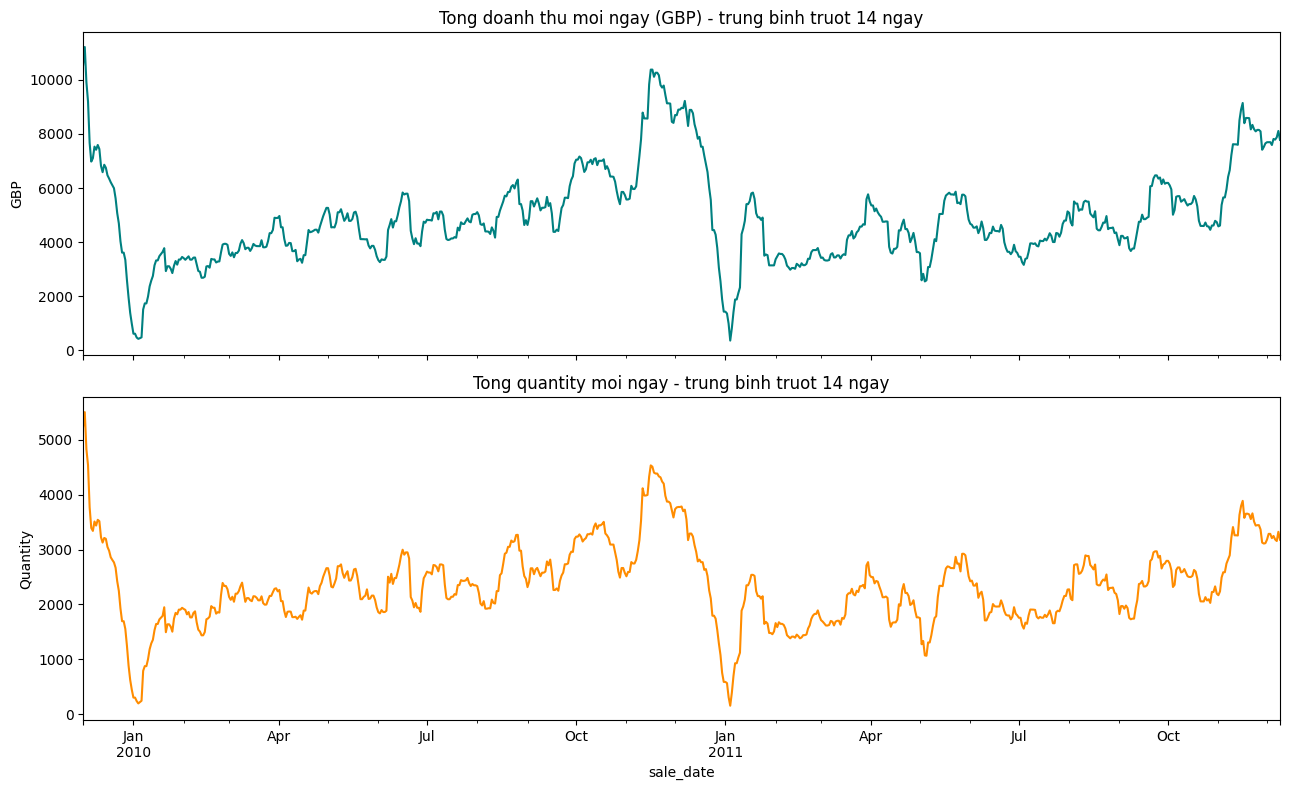

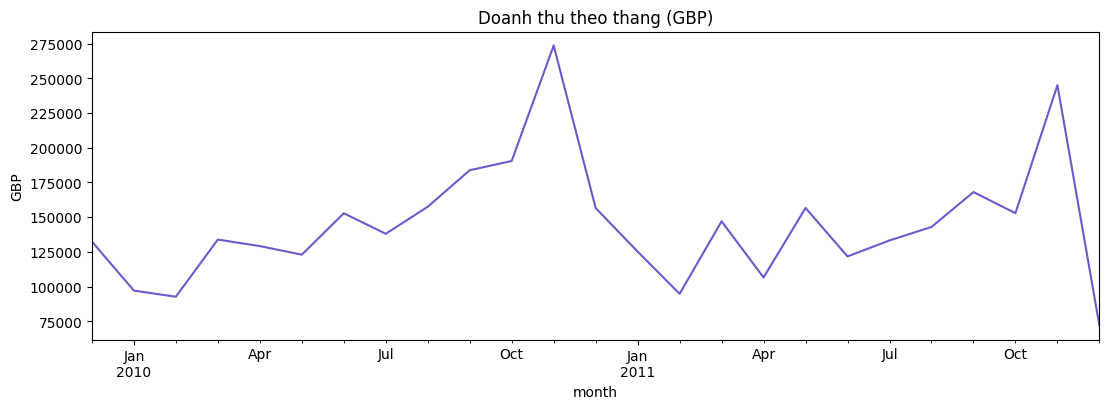

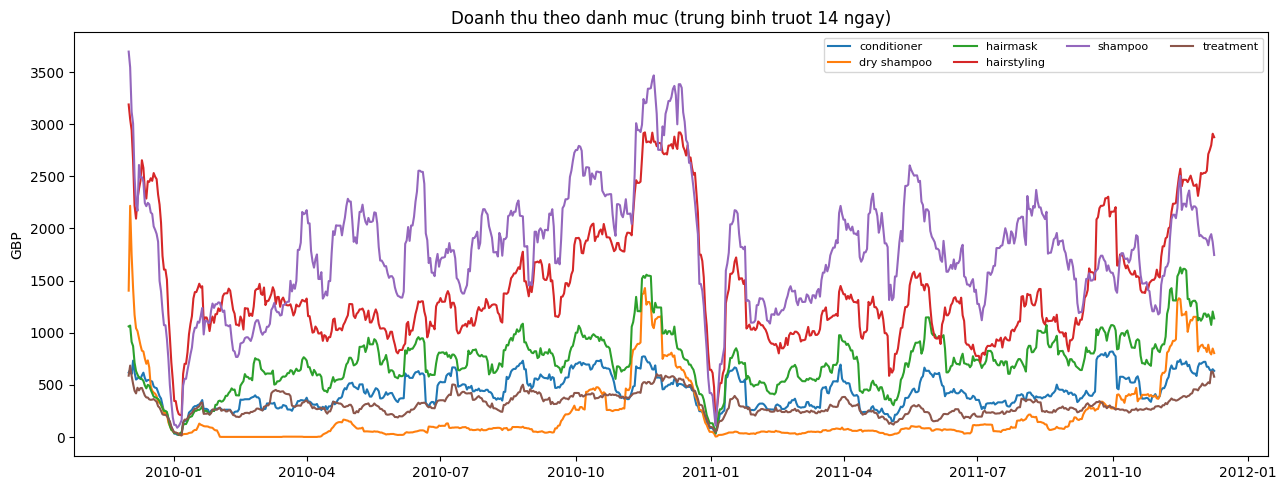

In [2]:
quality = pd.DataFrame({
    "metric": [
        "rows", "unique products", "unique dates", "duplicate product-date keys",
        "missing values total", "zero-sale rows", "zero-sale share",
        "quantity total", "revenue total (GBP)", "outlier source lines",
    ],
    "value": [
        len(df), df["product_id"].nunique(), df["sale_date"].nunique(),
        int(df.duplicated(["sale_date", "product_id"]).sum()),
        int(df.isna().sum().sum()), int(df["is_zero_sale_day"].sum()),
        df["is_zero_sale_day"].mean(), int(df["quantity_sold"].sum()),
        df["revenue_gbp"].sum(), int(df["outlier_source_lines"].sum()),
    ],
})
display(quality)
display(df[["quantity_sold", "revenue_gbp", "unit_price_gbp"]].describe(percentiles=[.5, .9, .99]).T)
display(df.isna().sum().rename("missing_count").to_frame())

daily_all = df.groupby("sale_date").agg(
    revenue_gbp=("revenue_gbp", "sum"),
    quantity_sold=("quantity_sold", "sum"),
).sort_index()
category_daily = df.groupby(["sale_date", "category"], as_index=False).agg(
    revenue_gbp=("revenue_gbp", "sum"), quantity_sold=("quantity_sold", "sum")
)

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
daily_all["revenue_gbp"].rolling(14, min_periods=1).mean().plot(ax=axes[0], color="teal")
axes[0].set_title("Tong doanh thu moi ngay (GBP) - trung binh truot 14 ngay")
axes[0].set_ylabel("GBP")
daily_all["quantity_sold"].rolling(14, min_periods=1).mean().plot(ax=axes[1], color="darkorange")
axes[1].set_title("Tong quantity moi ngay - trung binh truot 14 ngay")
axes[1].set_ylabel("Quantity")
plt.tight_layout()
plt.show()

monthly = df.assign(month=df["sale_date"].dt.to_period("M").dt.to_timestamp()).groupby("month").agg(
    revenue_gbp=("revenue_gbp", "sum"), quantity_sold=("quantity_sold", "sum")
)
monthly["revenue_gbp"].plot(figsize=(13, 4), title="Doanh thu theo thang (GBP)", color="slateblue")
plt.ylabel("GBP")
plt.show()

fig, ax = plt.subplots(figsize=(13, 5))
for category, group in category_daily.groupby("category"):
    ax.plot(group["sale_date"], group["revenue_gbp"].rolling(14, min_periods=1).mean(), label=category)
ax.set_title("Doanh thu theo danh muc (trung binh truot 14 ngay)")
ax.set_ylabel("GBP")
ax.legend(ncol=4, fontsize=8)
plt.tight_layout()
plt.show()

## 3. Data Analytics

So sanh danh muc/san pham dua tren tong doanh thu GBP va quantity nguon. Do gia GBP la gia cua giao dich nguon va ten HairCare chi la nhan mo phong, cac bang nay chi minh hoa cach lam analytics, khong phai xep hang san pham HairCare that.

,category,category_vi,product_count,revenue_gbp,quantity_sold,zero_sale_rate,outlier_lines,revenue_share
4,shampoo,Dầu gội,10,"1,315,481.81","552,648",22.8%,695,36.3%
3,hairstyling,Tạo kiểu tóc,23,"1,059,465.09","447,447",31.8%,431,29.2%
2,hairmask,Ủ tóc,11,"540,162.79","374,211",26.6%,334,14.9%
0,conditioner,Dầu xả,8,"322,240.73","204,884",27.4%,252,8.9%
5,treatment,Dưỡng tóc,5,"229,252.98","89,758",27.0%,40,6.3%
1,dry shampoo,Dầu gội khô,2,"159,857.04","52,091",44.3%,53,4.4%


,product_id,product_name,category,revenue_gbp,quantity_sold,active_days,zero_sale_rate
8,8161091485913,Color Care Shampoo,shampoo,"331,084.27","26,519",514,30.4%
0,8161090633945,Blonde Perfecting Purple Shampoo,shampoo,"261,509.93","94,839",603,18.4%
4,8161091289305,Clarifying Shampoo,shampoo,"182,999.67","97,350",589,20.3%
18,8161092731097,Hydrating Shampoo,shampoo,"148,395.98","28,216",541,26.8%
49,8513169162457,Frizz Control Shampoo,shampoo,"129,681.08","80,293",582,21.2%
13,8161091748057,Dry Shampoo Dark Tones,dry shampoo,"117,884.19","35,126",306,58.6%
5,8161091322073,Cocoa Color Depositing Mask,hairmask,"79,552.50","88,537",563,23.8%
7,8161091453145,Copper Color Depositing Mask,hairmask,"76,385.20","39,467",537,27.3%
17,8161091977433,Extra Volume Shampoo,shampoo,"71,396.14","40,506",594,19.6%
54,8957917987033,Scalp Balancing Conditioner,conditioner,"69,108.21","37,113",552,25.3%


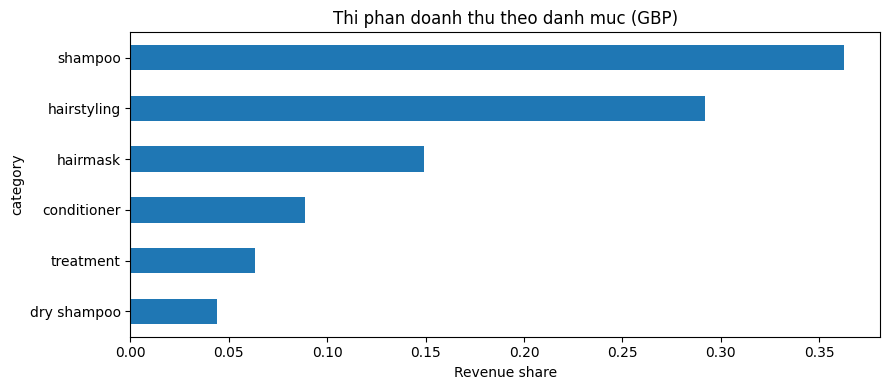

In [3]:
category_analytics = df.groupby(["category", "category_vi"], as_index=False).agg(
    product_count=("product_id", "nunique"),
    revenue_gbp=("revenue_gbp", "sum"),
    quantity_sold=("quantity_sold", "sum"),
    zero_sale_rate=("is_zero_sale_day", "mean"),
    outlier_lines=("outlier_source_lines", "sum"),
).sort_values("revenue_gbp", ascending=False)
category_analytics["revenue_share"] = category_analytics["revenue_gbp"] / category_analytics["revenue_gbp"].sum()
display(category_analytics.style.format({
    "revenue_gbp": "{:,.2f}", "quantity_sold": "{:,.0f}",
    "zero_sale_rate": "{:.1%}", "revenue_share": "{:.1%}",
}))

product_analytics = df.groupby(["product_id", "product_name", "category"], as_index=False).agg(
    revenue_gbp=("revenue_gbp", "sum"),
    quantity_sold=("quantity_sold", "sum"),
    active_days=("is_zero_sale_day", lambda values: int((~values).sum())),
    zero_sale_rate=("is_zero_sale_day", "mean"),
)
display(product_analytics.nlargest(10, "revenue_gbp").style.format({
    "revenue_gbp": "{:,.2f}", "quantity_sold": "{:,.0f}", "zero_sale_rate": "{:.1%}"
}))

category_analytics.sort_values("revenue_share")[ ["category", "revenue_share"] ].set_index("category").plot(
    kind="barh", legend=False, figsize=(9, 4), title="Thi phan doanh thu theo danh muc (GBP)"
)
plt.xlabel("Revenue share")
plt.tight_layout()
plt.show()

## 4. Xu ly va tao dac trung chuoi thoi gian

- Khong xao tron du lieu; giu panel ngay x san pham.
- Tao dac trung lich (thu, thang, tinh chu ky) va lag/rolling theo tung san pham.
- Tat ca rolling deu `shift(1)` truoc khi tinh, nen ngay t khong nhin thay target ngay t.
- Khong dung gia USD tu catalog, `unit_price_gbp` trong ngay du bao, hay cot thong tin tuong lai.
- Dung ba cua so validation lien tiep, moi cua so 28 ngay, de chon mo hinh; 60 ngay cuoi duoc giu rieng lam test cuoi.
- Cac diem validation/test la rolling one-step-ahead: moi ngay du bao co the dung target thuc cua ngay truoc.

In [4]:
TARGETS = {"revenue_gbp": "Revenue (GBP)", "quantity_sold": "Quantity"}
LAGS = [1, 7, 14, 21, 28, 35, 42, 56]
ROLLING_WINDOWS = [7, 14, 28, 56]
ROLLING_STD_WINDOWS = [14, 28]
CATEGORY_COL = "category"
CAT_FEATURES = ["product_id", CATEGORY_COL]
CALENDAR_FEATURES = [
    "day_of_week", "day_of_week_sin", "day_of_week_cos", "month",
    "day_of_year_sin", "day_of_year_cos",
]

def add_calendar_features(frame, origin_date):
    result = frame.copy()
    day_of_week = result["sale_date"].dt.dayofweek
    day_of_year = result["sale_date"].dt.dayofyear
    result["day_of_week"] = day_of_week
    result["month"] = result["sale_date"].dt.month
    result["day_of_week_sin"] = np.sin(2 * np.pi * day_of_week / 7)
    result["day_of_week_cos"] = np.cos(2 * np.pi * day_of_week / 7)
    result["day_of_year_sin"] = np.sin(2 * np.pi * day_of_year / 365.25)
    result["day_of_year_cos"] = np.cos(2 * np.pi * day_of_year / 365.25)
    return result

origin_date = df["sale_date"].min()
feature_frames = []
for target in TARGETS:
    part = df[["sale_date", "product_id", "product_name", "category", target]].copy()
    part = part.sort_values(["product_id", "sale_date"]).reset_index(drop=True)
    grouped = part.groupby("product_id", sort=False)[target]
    for lag in LAGS:
        part[f"lag_{lag}"] = grouped.shift(lag)
    for window in ROLLING_WINDOWS:
        part[f"rolling_mean_{window}"] = grouped.transform(
            lambda values: values.shift(1).rolling(window, min_periods=window).mean()
        )
    for window in ROLLING_STD_WINDOWS:
        part[f"rolling_std_{window}"] = grouped.transform(
            lambda values: values.shift(1).rolling(window, min_periods=window).std()
        )
    part = add_calendar_features(part, origin_date)
    part["target_name"] = target
    feature_frames.append(part)

model_data = pd.concat(feature_frames, ignore_index=True)
LAG_FEATURES = (
    [f"lag_{lag}" for lag in LAGS]
    + [f"rolling_mean_{window}" for window in ROLLING_WINDOWS]
    + [f"rolling_std_{window}" for window in ROLLING_STD_WINDOWS]
)
NUM_FEATURES = CALENDAR_FEATURES + LAG_FEATURES
FEATURES = CAT_FEATURES + NUM_FEATURES
# Moi target duoc feature-ize rieng; cot target khong lien quan co the null.
model_data = model_data.dropna(subset=FEATURES + ["target_name"])
holdout_start = df["sale_date"].max() - pd.Timedelta(days=HOLDOUT_DAYS - 1)
validation_windows = [
    (holdout_start - pd.Timedelta(days=84), holdout_start - pd.Timedelta(days=57)),
    (holdout_start - pd.Timedelta(days=56), holdout_start - pd.Timedelta(days=29)),
    (holdout_start - pd.Timedelta(days=28), holdout_start - pd.Timedelta(days=1)),
]
print(f"Validation: 3 cua so x 28 ngay truoc {holdout_start:%Y-%m-%d}")
print(f"Final holdout: {holdout_start:%Y-%m-%d} -> {df['sale_date'].max():%Y-%m-%d} ({HOLDOUT_DAYS} ngay)")
print(f"Rows after lag warm-up: {len(model_data):,}; features: {len(FEATURES)}")
print(f"Warm-up drops the first {max(LAGS)} days per product because lag_{max(LAGS)} is unavailable.")

Validation: 3 cua so x 28 ngay truoc 2011-10-11
Final holdout: 2011-10-11 -> 2011-12-09 (60 ngay)
Rows after lag warm-up: 80,594; features: 22
Warm-up drops the first 56 days per product because lag_56 is unavailable.


## 5. Train va so sanh mo hinh

So sanh seasonal naive voi Random Forest, Extra Trees va HistGradientBoosting. Seasonal naive la moc tham chieu; Random Forest/Extra Trees la tap hop cay bagging; HistGradientBoosting hoc noi tiep cac cay nho de sua loi. Ba cua so validation chi dung du lieu truoc final holdout; chon theo WAPE trung binh, sau do danh gia tren 60 ngay holdout.

Cac target lech va co spike duoc bien doi `log1p` khi fit, sau do chuyen nguoc bang `expm1`; khong cat hay sua target goc. Dac trung lag/rolling duoc mo rong den 56 ngay, bo `time_index` de tranh ngoai suy xu huong tuyen tinh khong on dinh.

WAPE la chi so chinh: tong sai so tuyet doi chia tong actual, nen khong chia tung dong va khong bi undefined o ngay zero. MAE la sai so trung binh tren moi cap san pham-ngay; RMSE phat nang hon voi spike; MAPE chi tinh tren actual > 0 va chi xem tham khao.

In [5]:
def build_model(model_name, num_features):
    numeric = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    preprocessor = ColumnTransformer([
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATURES),
        ("numeric", numeric, num_features),
    ], sparse_threshold=0)
    if model_name == "Random Forest":
        estimator = RandomForestRegressor(
            n_estimators=100, min_samples_leaf=3, max_features=0.8,
            n_jobs=-1, random_state=RANDOM_STATE,
        )
    elif model_name == "Extra Trees":
        estimator = ExtraTreesRegressor(
            n_estimators=100, min_samples_leaf=3, max_features=0.8,
            n_jobs=-1, random_state=RANDOM_STATE,
        )
    elif model_name == "HistGradientBoosting":
        estimator = HistGradientBoostingRegressor(
            max_iter=150, learning_rate=0.05, max_leaf_nodes=31,
            l2_regularization=5.0, random_state=RANDOM_STATE,
        )
    else:
        raise ValueError(f"Unknown model: {model_name}")
    return Pipeline([("preprocess", preprocessor), ("model", estimator)])

def regression_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.maximum(np.asarray(predicted, dtype=float), 0)
    abs_error = np.abs(actual - predicted)
    positive = actual > 0
    denominator = np.abs(actual) + np.abs(predicted)
    smape_terms = np.divide(2 * abs_error, denominator, out=np.zeros_like(abs_error), where=denominator > 0)
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "WAPE": abs_error.sum() / max(np.abs(actual).sum(), 1e-12),
        "MAPE_nonzero": np.mean(abs_error[positive] / actual[positive]) if positive.any() else np.nan,
        "sMAPE": smape_terms.mean(),
    }

MODEL_NAMES = ["Random Forest", "Extra Trees", "HistGradientBoosting"]
cv_rows = []
for target in TARGETS:
    target_frame = model_data.loc[model_data["target_name"].eq(target)].copy()
    for fold_number, (validation_start, validation_end) in enumerate(validation_windows, start=1):
        train = target_frame.loc[target_frame["sale_date"] < validation_start]
        validation = target_frame.loc[target_frame["sale_date"].between(validation_start, validation_end)]
        baseline = validation[f"lag_7"].to_numpy()
        cv_rows.append({
            "target": target, "model": "Seasonal Naive (lag 7)", "fold": fold_number,
            **regression_metrics(validation[target], baseline),
        })
        for model_name in MODEL_NAMES:
            model = build_model(model_name, NUM_FEATURES)
            model.fit(train[FEATURES], np.log1p(train[target]))
            predicted = np.maximum(np.expm1(model.predict(validation[FEATURES])), 0)
            cv_rows.append({
                "target": target, "model": model_name, "fold": fold_number,
                **regression_metrics(validation[target], predicted),
            })

cv_results = pd.DataFrame(cv_rows)
cv_summary = cv_results.groupby(["target", "model"], as_index=False).agg(
    mean_WAPE=("WAPE", "mean"), std_WAPE=("WAPE", "std"), mean_MAE=("MAE", "mean"),
).sort_values(["target", "mean_WAPE"])
display(cv_summary.style.format({"mean_WAPE": "{:.1%}", "std_WAPE": "{:.1%}", "mean_MAE": "{:,.2f}"}))
best_models = cv_summary.sort_values("mean_WAPE").groupby("target", as_index=False).first()[["target", "model", "mean_WAPE"]]
display(best_models)

# Evaluate every candidate on the final holdout for comparison; selection remains based on validation only.
holdout_rows = []
predictions = {}
fitted_models = {}
for target in TARGETS:
    target_frame = model_data.loc[model_data["target_name"].eq(target)].copy()
    train = target_frame.loc[target_frame["sale_date"] < holdout_start]
    test = target_frame.loc[target_frame["sale_date"] >= holdout_start].copy()
    candidate_names = ["Seasonal Naive (lag 7)"] + MODEL_NAMES
    chosen_name = best_models.loc[best_models["target"].eq(target), "model"].iloc[0]
    for model_name in candidate_names:
        if model_name == "Seasonal Naive (lag 7)":
            predicted = np.maximum(test["lag_7"].to_numpy(), 0)
        else:
            model = build_model(model_name, NUM_FEATURES)
            model.fit(train[FEATURES], np.log1p(train[target]))
            predicted = np.maximum(np.expm1(model.predict(test[FEATURES])), 0)
            fitted_models[(target, model_name)] = model
        predictions[(target, model_name)] = (test, predicted)
        holdout_rows.append({
            "target": target, "model": model_name, "selected_by_validation": model_name == chosen_name,
            **regression_metrics(test[target], predicted),
        })

holdout_scores = pd.DataFrame(holdout_rows)
display(holdout_scores.style.format({"MAE": "{:,.3f}", "RMSE": "{:,.3f}", "WAPE": "{:.1%}", "MAPE_nonzero": "{:.1%}", "sMAPE": "{:.1%}"}))
print("Cot selected_by_validation danh dau model chon truoc khi xem ket qua holdout.")
for result in holdout_scores.loc[holdout_scores["selected_by_validation"]].itertuples(index=False):
    if result.WAPE > 0.20:
        print(f"Can tiep tuc cai thien {result.target}: holdout WAPE={result.WAPE:.1%}.")

,target,model,mean_WAPE,std_WAPE,mean_MAE
1,quantity_sold,HistGradientBoosting,73.7%,2.2%,30.67
0,quantity_sold,Extra Trees,74.2%,1.7%,30.87
2,quantity_sold,Random Forest,74.4%,2.3%,30.92
3,quantity_sold,Seasonal Naive (lag 7),107.5%,4.4%,44.58
5,revenue_gbp,HistGradientBoosting,70.2%,1.8%,60.96
4,revenue_gbp,Extra Trees,70.3%,2.4%,61.07
6,revenue_gbp,Random Forest,71.1%,2.0%,61.78
7,revenue_gbp,Seasonal Naive (lag 7),99.6%,2.4%,86.30


,target,model,mean_WAPE
0,quantity_sold,HistGradientBoosting,0.737461
1,revenue_gbp,HistGradientBoosting,0.701654


,target,model,selected_by_validation,MAE,RMSE,WAPE,MAPE_nonzero,sMAPE
0,revenue_gbp,Seasonal Naive (lag 7),False,99.375,262.066,84.3%,204.2%,78.9%
1,revenue_gbp,Random Forest,False,75.136,213.974,63.7%,121.0%,67.8%
2,revenue_gbp,Extra Trees,False,75.011,209.234,63.6%,123.7%,66.7%
3,revenue_gbp,HistGradientBoosting,True,75.120,215.707,63.7%,126.8%,91.3%
4,quantity_sold,Seasonal Naive (lag 7),False,48.564,134.177,95.5%,250.4%,82.2%
5,quantity_sold,Random Forest,False,35.129,110.449,69.1%,142.0%,68.6%
6,quantity_sold,Extra Trees,False,34.499,108.235,67.8%,144.3%,67.4%
7,quantity_sold,HistGradientBoosting,True,35.111,111.147,69.0%,146.2%,92.5%


Cot selected_by_validation danh dau model chon truoc khi xem ket qua holdout.
Can tiep tuc cai thien revenue_gbp: holdout WAPE=63.7%.
Can tiep tuc cai thien quantity_sold: holdout WAPE=69.0%.


## 6. Phan tich loi tren holdout

Tong hop actual va forecast theo danh muc bang mo hinh duoc chon tren validation. Final holdout van duoc giu rieng, khong dung de chon model.

,category,actual,predicted,WAPE,target,selected_model
0,conditioner,"33,763.21","19,972.72",69.8%,revenue_gbp,HistGradientBoosting
1,dry shampoo,"47,171.54","23,500.22",58.6%,revenue_gbp,HistGradientBoosting
2,hairmask,"67,825.81","38,782.19",69.0%,revenue_gbp,HistGradientBoosting
3,hairstyling,"133,160.77","72,539.23",67.3%,revenue_gbp,HistGradientBoosting
4,shampoo,"110,892.62","76,725.14",56.5%,revenue_gbp,HistGradientBoosting
5,treatment,"24,646.60","13,836.83",63.4%,revenue_gbp,HistGradientBoosting
6,conditioner,"16,961.00","10,383.90",73.1%,quantity_sold,HistGradientBoosting
7,dry shampoo,"13,897.00","6,663.95",59.9%,quantity_sold,HistGradientBoosting
8,hairmask,"46,873.00","20,734.68",77.1%,quantity_sold,HistGradientBoosting
9,hairstyling,"48,488.00","26,656.95",70.8%,quantity_sold,HistGradientBoosting


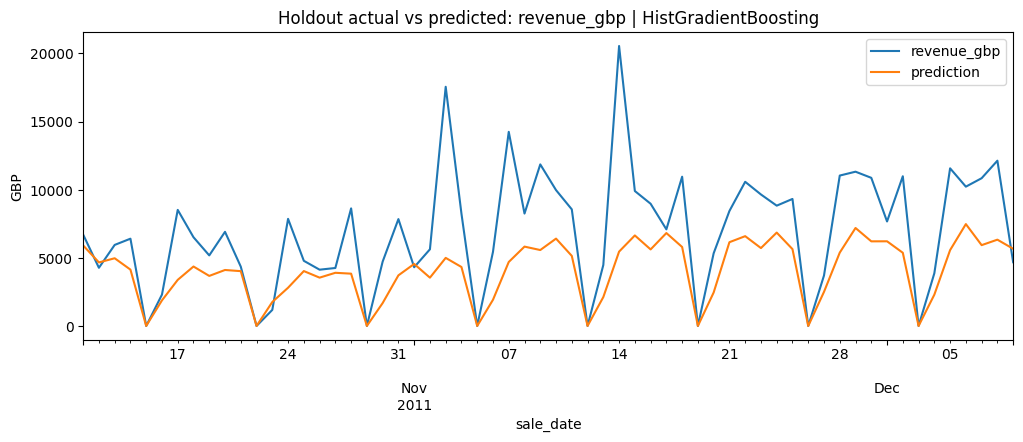

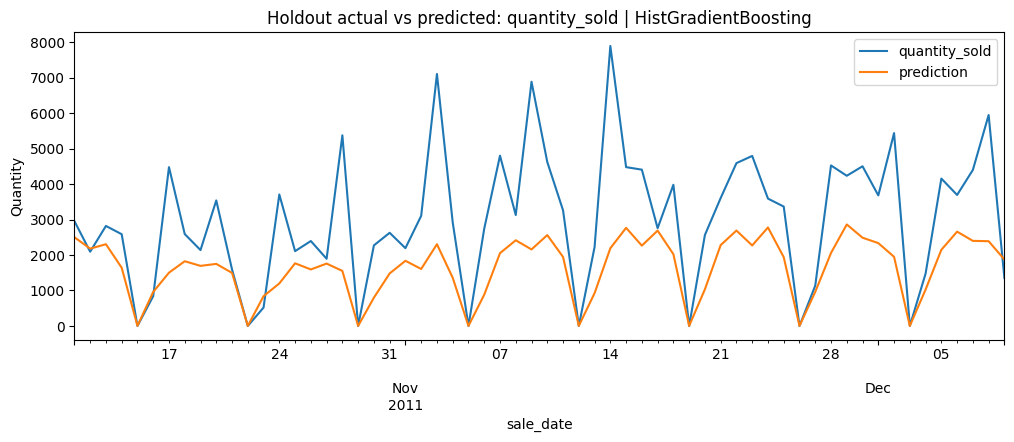

In [6]:
category_eval_rows = []
for target in TARGETS:
    chosen_name = best_models.loc[best_models["target"].eq(target), "model"].iloc[0]
    test, predicted = predictions[(target, chosen_name)]
    scored = test[["sale_date", "product_id", "product_name", "category", target]].copy()
    scored["prediction"] = predicted
    summary = scored.groupby("category", as_index=False).agg(
        actual=(target, "sum"), predicted=("prediction", "sum")
    )
    errors = scored.assign(abs_error=(scored[target] - scored["prediction"]).abs()).groupby("category")["abs_error"].sum()
    summary["WAPE"] = summary["category"].map(errors) / summary["actual"].replace(0, np.nan)
    summary["target"] = target
    summary["selected_model"] = chosen_name
    category_eval_rows.append(summary)
category_eval = pd.concat(category_eval_rows, ignore_index=True)
display(category_eval.style.format({"actual": "{:,.2f}", "predicted": "{:,.2f}", "WAPE": "{:.1%}"}))

for target in TARGETS:
    chosen_name = best_models.loc[best_models["target"].eq(target), "model"].iloc[0]
    test, predicted = predictions[(target, chosen_name)]
    plot_frame = test[["sale_date", target]].copy()
    plot_frame["prediction"] = predicted
    plot_frame = plot_frame.groupby("sale_date")[[target, "prediction"]].sum()
    plot_frame.plot(figsize=(12, 4), title=f"Holdout actual vs predicted: {target} | {chosen_name}")
    plt.ylabel("GBP" if target == "revenue_gbp" else "Quantity")
    plt.show()

## 7. Du bao 14 ngay va minh hoa goi y nhap hang

Mo hinh tot nhat tren holdout cho tung target duoc fit lai tren toan bo lich su. Du bao tuong lai duoc tao de quy: moi ngay dung cac lag/rolling tu lich su den hom truoc va gia tri model du bao. So ngay du bao phai lon hon hoac bang `LEAD_TIME_DAYS + REVIEW_PERIOD_DAYS`.

Chinh sua 3 gia dinh dau cell cau hinh (`DEMO_CURRENT_STOCK_PER_PRODUCT`, lead time, review period) theo kich ban demo. Safety stock duoc minh hoa bang `z * do lech chuan nhu cau ngay 90 ngay gan nhat * sqrt(lead time)`; do lech chuan chi winsorize tai p99 cho phep tinh safety stock de giam anh huong outlier. Target huan luyen va du bao van giu nguyen. Day la heuristic, khong phai tham so ton kho duoc hoc tu Online Retail II.

In [7]:
required_horizon = LEAD_TIME_DAYS + REVIEW_PERIOD_DAYS
if FORECAST_DAYS < required_horizon:
    raise ValueError("FORECAST_DAYS phai >= lead time + review period.")

def calendar_row(date, product_id, category):
    row = pd.DataFrame({
        "sale_date": [pd.Timestamp(date)],
        "product_id": pd.Series([str(product_id)], dtype="string"),
        "category": [category],
    })
    return add_calendar_features(row, origin_date)

def recursive_forecast(target, model, horizon):
    histories = {}
    metadata = df[["product_id", "product_name", "category"]].drop_duplicates("product_id").copy()
    metadata["product_id"] = metadata["product_id"].astype("string")
    for product_id, group in df.sort_values("sale_date").groupby("product_id", sort=False):
        histories[str(product_id)] = group[target].astype(float).tolist()
    future_dates = pd.date_range(df["sale_date"].max() + pd.Timedelta(days=1), periods=horizon, freq="D")
    output = []
    for date in future_dates:
        feature_rows = []
        product_ids = metadata["product_id"].tolist()
        for item in metadata.itertuples(index=False):
            history = histories[str(item.product_id)]
            row = calendar_row(date, item.product_id, item.category)
            for lag in LAGS:
                row[f"lag_{lag}"] = history[-lag]
            for window in ROLLING_WINDOWS:
                row[f"rolling_mean_{window}"] = float(np.mean(history[-window:]))
            for window in ROLLING_STD_WINDOWS:
                row[f"rolling_std_{window}"] = float(np.std(history[-window:], ddof=1))
            feature_rows.append(row)
        batch = pd.concat(feature_rows, ignore_index=True)
        if model is None:
            batch["prediction"] = batch["lag_7"].to_numpy()
        else:
            batch["prediction"] = np.maximum(np.expm1(model.predict(batch[FEATURES])), 0)
        for item, predicted in zip(metadata.itertuples(index=False), batch["prediction"]):
            histories[str(item.product_id)].append(float(predicted))
        batch["target"] = target
        output.append(batch[["sale_date", "product_id", "category", "prediction", "target"]])
    return pd.concat(output, ignore_index=True).merge(metadata, on=["product_id", "category"], how="left", validate="many_to_one")

future_parts = []
for target in TARGETS:
    selected_name = best_models.loc[best_models["target"].eq(target), "model"].iloc[0]
    full_target = model_data.loc[model_data["target_name"].eq(target)]
    if selected_name == "Seasonal Naive (lag 7)":
        final_model = None
    else:
        final_model = build_model(selected_name, NUM_FEATURES)
        final_model.fit(full_target[FEATURES], np.log1p(full_target[target]))
        fitted_models[(target, selected_name, "full")] = final_model
    future_parts.append(recursive_forecast(target, final_model, FORECAST_DAYS))

future_forecast = pd.concat(future_parts, ignore_index=True)
forecast_wide = future_forecast.pivot_table(
    index=["sale_date", "product_id", "product_name", "category"],
    columns="target", values="prediction", aggfunc="first",
).reset_index()
forecast_wide.columns.name = None
forecast_wide = forecast_wide.rename(columns={"revenue_gbp": "forecast_revenue_gbp", "quantity_sold": "forecast_quantity"})
display(forecast_wide.head(10))
display(forecast_wide.groupby("sale_date", as_index=False).agg(
    forecast_revenue_gbp=("forecast_revenue_gbp", "sum"),
    forecast_quantity=("forecast_quantity", "sum"),
).head())

,sale_date,product_id,product_name,category,forecast_quantity,forecast_revenue_gbp
0,2011-12-10,8161090633945,Blonde Perfecting Purple Shampoo,shampoo,0.012932,0.000000
1,2011-12-10,8161090666713,Blonde Perfecting Purple Conditioner,conditioner,0.000000,0.000000
2,2011-12-10,8161090765017,Intense Smoothing Serum,treatment,0.000000,0.000000
3,2011-12-10,8161091223769,Bordeaux Color Depositing Mask,hairmask,0.000000,0.000000
4,2011-12-10,8161091289305,Clarifying Shampoo,shampoo,0.019401,0.000000
5,2011-12-10,8161091322073,Cocoa Color Depositing Mask,hairmask,0.000000,0.000000
6,2011-12-10,8161091354841,Color Care Conditioner,conditioner,0.000000,0.000000
7,2011-12-10,8161091453145,Copper Color Depositing Mask,hairmask,0.014397,0.000000
8,2011-12-10,8161091485913,Color Care Shampoo,shampoo,0.025358,0.028290
9,2011-12-10,8161091551449,Coral Color Depositing Mask,hairmask,0.022757,0.016196


,sale_date,forecast_revenue_gbp,forecast_quantity
0,2011-12-10,0.924193,0.783024
1,2011-12-11,1593.456897,595.822431
2,2011-12-12,4472.657917,1623.524846
3,2011-12-13,5776.708264,1899.344660
4,2011-12-14,3974.448535,1643.442575


In [8]:
forecast_window = forecast_wide.loc[
    forecast_wide["sale_date"] <= df["sale_date"].max() + pd.Timedelta(days=required_horizon)
]
forecast_demand = forecast_window.groupby(["product_id", "product_name", "category"], as_index=False).agg(
    forecast_quantity=("forecast_quantity", "sum"),
    forecast_revenue_gbp=("forecast_revenue_gbp", "sum"),
)
recent = df.loc[df["sale_date"] > df["sale_date"].max() - pd.Timedelta(days=90)]
def winsorized_std(values):
    # Limit outlier influence in this safety-stock heuristic only; model targets stay unchanged.
    cap = values.quantile(0.99)
    return values.clip(upper=cap).std()

demand_std = recent.groupby("product_id")["quantity_sold"].agg(winsorized_std).fillna(0)
demand_std = demand_std.rename("recent_daily_quantity_std_winsorized")
inventory_advice = forecast_demand.join(demand_std, on="product_id")
inventory_advice["current_stock_demo"] = DEMO_CURRENT_STOCK_PER_PRODUCT
inventory_advice["safety_stock_demo"] = np.ceil(
    SAFETY_STOCK_Z * inventory_advice["recent_daily_quantity_std_winsorized"] * np.sqrt(LEAD_TIME_DAYS)
).astype(int)
inventory_advice["recommended_order_qty_demo"] = np.ceil(np.maximum(
    0,
    inventory_advice["forecast_quantity"] + inventory_advice["safety_stock_demo"]
    - inventory_advice["current_stock_demo"],
)).astype(int)
inventory_advice["lead_time_days_assumed"] = LEAD_TIME_DAYS
inventory_advice["review_period_days_assumed"] = REVIEW_PERIOD_DAYS
inventory_advice["currency_revenue"] = "GBP"
inventory_advice = inventory_advice.sort_values("recommended_order_qty_demo", ascending=False)
display(inventory_advice.head(15).style.format({
    "forecast_quantity": "{:,.1f}", "forecast_revenue_gbp": "{:,.2f}",
    "recent_daily_quantity_std_winsorized": "{:,.1f}",
}))

output_path = DATA_PATH.parent.parent / "A_Plan" / "results" / "demo_inventory_recommendations.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)
inventory_advice.to_csv(output_path, index=False, encoding="utf-8-sig")
print(f"Da luu khuyen nghi mo phong: {output_path}")
print("Khong dung ket qua nay de dat hang that; current_stock va cac tham so ton kho la gia dinh demo.")

,product_id,product_name,category,forecast_quantity,forecast_revenue_gbp,recent_daily_quantity_std_winsorized,current_stock_demo,safety_stock_demo,recommended_order_qty_demo,lead_time_days_assumed,review_period_days_assumed,currency_revenue
5,8161091322073,Cocoa Color Depositing Mask,hairmask,930.0,"1,809.50",453.5,50,1980,2861,7,7,GBP
13,8161091748057,Dry Shampoo Dark Tones,dry shampoo,"1,030.8","3,266.18",183.7,50,803,1784,7,7,GBP
4,8161091289305,Clarifying Shampoo,shampoo,807.2,"1,667.14",213.0,50,931,1689,7,7,GBP
49,8513169162457,Frizz Control Shampoo,shampoo,814.6,"1,249.39",122.9,50,537,1302,7,7,GBP
0,8161090633945,Blonde Perfecting Purple Shampoo,shampoo,691.9,"2,068.84",104.9,50,458,1100,7,7,GBP
10,8161091584217,Curl Control Mousse,hairstyling,376.1,567.68,150.9,50,659,986,7,7,GBP
47,8210592465113,Curl Enhancing Shampoo,shampoo,404.3,269.35,100.4,50,439,794,7,7,GBP
15,8161091813593,Dry Texture Spray,hairstyling,493.1,599.32,73.6,50,322,766,7,7,GBP
21,8161092862169,Intense Curl Cream,hairstyling,387.3,552.74,71.2,50,311,649,7,7,GBP
22,8161092894937,Intense Hydrating Mask,hairmask,137.1,208.24,123.6,50,540,628,7,7,GBP


Da luu khuyen nghi mo phong: E:\UEL\WebML_Project\data\ml\A_Plan\results\demo_inventory_recommendations.csv
Khong dung ket qua nay de dat hang that; current_stock va cac tham so ton kho la gia dinh demo.


## 8. Thu them mo hinh va gom target theo tuan

Daily forecast kho vi moi SKU co nhieu ngay zero va giao dich spike. De phu hop hon voi quyet dinh dat hang theo lead time, cell nay gom doanh thu/quantity thanh tong tuan va thu LightGBM, XGBoost ben canh HistGradientBoosting. So sanh bang ba cua so validation 4 tuan truoc holdout va danh gia holdout theo tuan. WAPE theo tuan khong so sanh truc tiep voi WAPE theo ngay vi target va don vi du bao da gom theo thoi gian.

In [9]:
weekly_panel = (
    df.set_index("sale_date")
    .groupby("product_id")[["quantity_sold", "revenue_gbp"]]
    .resample("W-SUN").sum()
    .reset_index()
    .merge(df[["product_id", "category", "product_name"]].drop_duplicates("product_id"),
           on="product_id", how="left", validate="many_to_one")
)
weekly_holdout_start = holdout_start - pd.Timedelta(days=holdout_start.weekday())
weekly_validation_windows = [
    (start, start + pd.Timedelta(days=27))
    for start in [
        weekly_holdout_start - pd.Timedelta(weeks=12),
        weekly_holdout_start - pd.Timedelta(weeks=8),
        weekly_holdout_start - pd.Timedelta(weeks=4),
    ]
]
WEEKLY_LAGS = [1, 2, 4, 8, 13, 26]
WEEKLY_ROLLING = [4, 8, 13]
weekly_feature_frames = []
for target in TARGETS:
    part = weekly_panel[["sale_date", "product_id", "category", "product_name", target]].copy()
    part = part.sort_values(["product_id", "sale_date"]).reset_index(drop=True)
    grouped = part.groupby("product_id", sort=False)[target]
    for lag in WEEKLY_LAGS:
        part[f"lag_{lag}"] = grouped.shift(lag)
    for window in WEEKLY_ROLLING:
        part[f"rolling_mean_{window}"] = grouped.transform(
            lambda values: values.shift(1).rolling(window, min_periods=window).mean()
        )
    week_of_year = part["sale_date"].dt.isocalendar().week.astype(int)
    part["week_of_year"] = week_of_year
    part["month"] = part["sale_date"].dt.month
    part["week_sin"] = np.sin(2 * np.pi * week_of_year / 52.18)
    part["week_cos"] = np.cos(2 * np.pi * week_of_year / 52.18)
    part["target_name"] = target
    weekly_feature_frames.append(part)

weekly_model_data = pd.concat(weekly_feature_frames, ignore_index=True)
WEEKLY_CATEGORICAL = ["product_id", "category"]
WEEKLY_NUMERIC = (
    [f"lag_{lag}" for lag in WEEKLY_LAGS]
    + [f"rolling_mean_{window}" for window in WEEKLY_ROLLING]
    + ["week_of_year", "month", "week_sin", "week_cos"]
)
WEEKLY_FEATURES = WEEKLY_CATEGORICAL + WEEKLY_NUMERIC
weekly_model_data = weekly_model_data.dropna(subset=WEEKLY_FEATURES + ["target_name"])

def build_weekly_model(model_name):
    preprocessing = ColumnTransformer([
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), WEEKLY_CATEGORICAL),
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]), WEEKLY_NUMERIC),
    ], sparse_threshold=0)
    if model_name == "HistGradientBoosting":
        estimator = HistGradientBoostingRegressor(
            max_iter=120, learning_rate=0.05, max_leaf_nodes=15,
            l2_regularization=5, random_state=RANDOM_STATE,
        )
    elif model_name == "LightGBM":
        estimator = LGBMRegressor(
            objective="regression_l1", n_estimators=120, learning_rate=0.03,
            num_leaves=7, min_child_samples=10, verbosity=-1,
            n_jobs=-1, random_state=RANDOM_STATE,
        )
    elif model_name == "XGBoost":
        estimator = XGBRegressor(
            objective="reg:squarederror", n_estimators=120, max_depth=3,
            learning_rate=0.03, min_child_weight=10, subsample=0.8,
            colsample_bytree=0.8, reg_lambda=10, n_jobs=-1,
            random_state=RANDOM_STATE,
        )
    else:
        raise ValueError(f"Unknown weekly model: {model_name}")
    return Pipeline([("preprocess", preprocessing), ("model", estimator)])

WEEKLY_MODEL_NAMES = ["HistGradientBoosting", "LightGBM", "XGBoost"]
weekly_cv_rows = []
for target in TARGETS:
    target_frame = weekly_model_data.loc[weekly_model_data["target_name"].eq(target)]
    for fold_number, (validation_start, validation_end) in enumerate(weekly_validation_windows, start=1):
        train = target_frame.loc[target_frame["sale_date"] < validation_start]
        validation = target_frame.loc[target_frame["sale_date"].between(validation_start, validation_end)]
        weekly_cv_rows.append({
            "target": target, "model": "Seasonal Naive (lag 1 week)", "fold": fold_number,
            **regression_metrics(validation[target], validation["lag_1"]),
        })
        for model_name in WEEKLY_MODEL_NAMES:
            model = build_weekly_model(model_name)
            model.fit(train[WEEKLY_FEATURES], np.log1p(train[target]))
            predicted = np.maximum(np.expm1(model.predict(validation[WEEKLY_FEATURES])), 0)
            weekly_cv_rows.append({
                "target": target, "model": model_name, "fold": fold_number,
                **regression_metrics(validation[target], predicted),
            })

weekly_cv_results = pd.DataFrame(weekly_cv_rows)
weekly_cv_summary = weekly_cv_results.groupby(["target", "model"], as_index=False).agg(
    mean_WAPE=("WAPE", "mean"), std_WAPE=("WAPE", "std"), mean_MAE=("MAE", "mean")
).sort_values(["target", "mean_WAPE"])
display(weekly_cv_summary.style.format({"mean_WAPE": "{:.1%}", "std_WAPE": "{:.1%}", "mean_MAE": "{:,.2f}"}))
weekly_best_models = weekly_cv_summary.sort_values("mean_WAPE").groupby("target", as_index=False).first()[
    ["target", "model", "mean_WAPE"]
]
display(weekly_best_models)

weekly_holdout_rows = []
weekly_holdout_predictions = {}
for target in TARGETS:
    target_frame = weekly_model_data.loc[weekly_model_data["target_name"].eq(target)]
    train = target_frame.loc[target_frame["sale_date"] < weekly_holdout_start]
    test = target_frame.loc[target_frame["sale_date"] >= weekly_holdout_start].copy()
    selected_model = weekly_best_models.loc[weekly_best_models["target"].eq(target), "model"].iloc[0]
    candidates = ["Seasonal Naive (lag 1 week)"] + WEEKLY_MODEL_NAMES
    for model_name in candidates:
        if model_name == "Seasonal Naive (lag 1 week)":
            predicted = np.maximum(test["lag_1"].to_numpy(), 0)
        else:
            model = build_weekly_model(model_name)
            model.fit(train[WEEKLY_FEATURES], np.log1p(train[target]))
            predicted = np.maximum(np.expm1(model.predict(test[WEEKLY_FEATURES])), 0)
        weekly_holdout_predictions[(target, model_name)] = (test, predicted)
        weekly_holdout_rows.append({
            "target": target, "model": model_name,
            "selected_by_validation": model_name == selected_model,
            **regression_metrics(test[target], predicted),
        })

weekly_holdout_scores = pd.DataFrame(weekly_holdout_rows)
display(weekly_holdout_scores.style.format({
    "MAE": "{:,.2f}", "RMSE": "{:,.2f}", "WAPE": "{:.1%}",
    "MAPE_nonzero": "{:.1%}", "sMAPE": "{:.1%}",
}))
print("Holdout gom theo tuan; cot selected_by_validation danh dau model chon truoc khi xem holdout.")

C:\Users\PHUONG THAO\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
C:\Users\PHUONG THAO\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
C:\Users\PHUONG THAO\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
C:\Users\PHUONG THAO\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packag

,target,model,mean_WAPE,std_WAPE,mean_MAE
1,quantity_sold,LightGBM,45.0%,1.3%,130.61
3,quantity_sold,XGBoost,45.0%,2.6%,131.02
0,quantity_sold,HistGradientBoosting,45.4%,1.8%,131.99
2,quantity_sold,Seasonal Naive (lag 1 week),58.3%,0.3%,169.14
5,revenue_gbp,LightGBM,41.8%,2.9%,255.24
7,revenue_gbp,XGBoost,42.7%,3.5%,260.80
4,revenue_gbp,HistGradientBoosting,43.2%,2.7%,263.45
6,revenue_gbp,Seasonal Naive (lag 1 week),53.0%,5.6%,324.59


,target,model,mean_WAPE
0,quantity_sold,LightGBM,0.450154
1,revenue_gbp,LightGBM,0.418093


C:\Users\PHUONG THAO\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
C:\Users\PHUONG THAO\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,target,model,selected_by_validation,MAE,RMSE,WAPE,MAPE_nonzero,sMAPE
0,revenue_gbp,Seasonal Naive (lag 1 week),False,370.01,668.40,46.4%,64.6%,46.3%
1,revenue_gbp,HistGradientBoosting,False,309.52,599.03,38.8%,52.3%,41.4%
2,revenue_gbp,LightGBM,True,323.54,656.43,40.6%,51.5%,41.5%
3,revenue_gbp,XGBoost,False,337.77,698.55,42.3%,51.1%,42.8%
4,quantity_sold,Seasonal Naive (lag 1 week),False,175.78,316.70,51.1%,76.1%,51.6%
5,quantity_sold,HistGradientBoosting,False,156.69,336.90,45.6%,61.8%,46.3%
6,quantity_sold,LightGBM,True,159.70,355.57,46.4%,61.5%,45.8%
7,quantity_sold,XGBoost,False,164.92,371.10,47.9%,59.4%,46.8%


Holdout gom theo tuan; cot selected_by_validation danh dau model chon truoc khi xem holdout.


### Du bao theo tuan cho kich ban nhap hang 14 ngay

Fit mo hinh duoc chon bang validation tren toan bo weekly history va du bao hai tuan tiep theo. Khuyen nghi ton kho duoi day dung tong nhu cau hai tuan du bao; safety stock tinh tu do lech chuan weekly demand gan day va cac gia dinh inventory khai bao o cell dau notebook.

In [10]:
def weekly_calendar_row(week_end, product_id, category):
    week_of_year = int(pd.Timestamp(week_end).isocalendar().week)
    return pd.DataFrame({
        "product_id": pd.Series([str(product_id)], dtype="string"),
        "category": [category],
        "lag_1": [np.nan], "lag_2": [np.nan], "lag_4": [np.nan],
        "lag_8": [np.nan], "lag_13": [np.nan], "lag_26": [np.nan],
        "rolling_mean_4": [np.nan], "rolling_mean_8": [np.nan],
        "rolling_mean_13": [np.nan], "week_of_year": [week_of_year],
        "month": [pd.Timestamp(week_end).month],
        "week_sin": [np.sin(2 * np.pi * week_of_year / 52.18)],
        "week_cos": [np.cos(2 * np.pi * week_of_year / 52.18)],
    })

def recursive_weekly_forecast(target, model, horizon_weeks):
    metadata = weekly_panel[["product_id", "product_name", "category"]].drop_duplicates("product_id").copy()
    metadata["product_id"] = metadata["product_id"].astype("string")
    histories = {
        str(product_id): group.sort_values("sale_date")[target].astype(float).tolist()
        for product_id, group in weekly_panel.groupby("product_id", sort=False)
    }
    future_dates = pd.date_range(
        weekly_panel["sale_date"].max() + pd.Timedelta(days=7),
        periods=horizon_weeks, freq="7D",
    )
    outputs = []
    for week_end in future_dates:
        rows = []
        for item in metadata.itertuples(index=False):
            history = histories[str(item.product_id)]
            row = weekly_calendar_row(week_end, item.product_id, item.category)
            for lag in WEEKLY_LAGS:
                row[f"lag_{lag}"] = history[-lag]
            for window in WEEKLY_ROLLING:
                row[f"rolling_mean_{window}"] = float(np.mean(history[-window:]))
            rows.append(row)
        batch = pd.concat(rows, ignore_index=True)
        batch["prediction"] = np.maximum(np.expm1(model.predict(batch[WEEKLY_FEATURES])), 0)
        for item, predicted in zip(metadata.itertuples(index=False), batch["prediction"]):
            histories[str(item.product_id)].append(float(predicted))
        batch["sale_date"] = week_end
        batch["target"] = target
        outputs.append(batch[["sale_date", "product_id", "category", "prediction", "target"]])
    return pd.concat(outputs, ignore_index=True).merge(
        metadata, on=["product_id", "category"], how="left", validate="many_to_one"
    )

weekly_future_parts = []
weekly_final_models = {}
for target in TARGETS:
    selected_model = weekly_best_models.loc[weekly_best_models["target"].eq(target), "model"].iloc[0]
    if selected_model == "Seasonal Naive (lag 1 week)":
        raise ValueError("Seasonal baseline recursive forecasting is not implemented; select a trained model.")
    full_target = weekly_model_data.loc[weekly_model_data["target_name"].eq(target)]
    final_model = build_weekly_model(selected_model)
    final_model.fit(full_target[WEEKLY_FEATURES], np.log1p(full_target[target]))
    weekly_final_models[target] = final_model
    weekly_future_parts.append(recursive_weekly_forecast(target, final_model, horizon_weeks=2))

weekly_future = pd.concat(weekly_future_parts, ignore_index=True)
weekly_forecast_wide = weekly_future.pivot_table(
    index=["sale_date", "product_id", "product_name", "category"],
    columns="target", values="prediction", aggfunc="first",
).reset_index()
weekly_forecast_wide.columns.name = None
weekly_forecast_wide = weekly_forecast_wide.rename(columns={
    "quantity_sold": "forecast_quantity", "revenue_gbp": "forecast_revenue_gbp"
})
display(weekly_forecast_wide.head(10))

recent_weekly = weekly_panel.sort_values("sale_date").groupby("product_id", sort=False).tail(13)
weekly_demand_std = recent_weekly.groupby("product_id")["quantity_sold"].agg(winsorized_std).rename("recent_weekly_quantity_std")
weekly_inventory_advice = weekly_forecast_wide.groupby(
    ["product_id", "product_name", "category"], as_index=False
).agg(
    forecast_quantity=("forecast_quantity", "sum"),
    forecast_revenue_gbp=("forecast_revenue_gbp", "sum"),
).join(weekly_demand_std, on="product_id")
weekly_inventory_advice["current_stock_demo"] = DEMO_CURRENT_STOCK_PER_PRODUCT
lead_weeks = int(np.ceil(LEAD_TIME_DAYS / 7))
weekly_inventory_advice["safety_stock_demo"] = np.ceil(
    SAFETY_STOCK_Z * weekly_inventory_advice["recent_weekly_quantity_std"] * np.sqrt(lead_weeks)
).astype(int)
weekly_inventory_advice["recommended_order_qty_demo"] = np.ceil(np.maximum(
    0, weekly_inventory_advice["forecast_quantity"]
    + weekly_inventory_advice["safety_stock_demo"]
    - weekly_inventory_advice["current_stock_demo"],
)).astype(int)
weekly_inventory_advice["lead_time_days_assumed"] = LEAD_TIME_DAYS
weekly_inventory_advice["review_period_days_assumed"] = REVIEW_PERIOD_DAYS
weekly_inventory_advice["forecast_granularity"] = "2 weekly periods"
weekly_inventory_advice = weekly_inventory_advice.sort_values(
    "recommended_order_qty_demo", ascending=False
)
display(weekly_inventory_advice.head(15).style.format({
    "forecast_quantity": "{:,.1f}", "forecast_revenue_gbp": "{:,.2f}",
    "recent_weekly_quantity_std": "{:,.1f}",
}))
weekly_output_path = DATA_PATH.parent.parent / "A_Plan" / "results" / "demo_inventory_recommendations_weekly.csv"
weekly_output_path.parent.mkdir(parents=True, exist_ok=True)
weekly_inventory_advice.to_csv(weekly_output_path, index=False, encoding="utf-8-sig")
print(f"Da luu khuyen nghi ton kho theo tuan: {weekly_output_path}")

C:\Users\PHUONG THAO\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
C:\Users\PHUONG THAO\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
C:\Users\PHUONG THAO\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
C:\Users\PHUONG THAO\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packag

,sale_date,product_id,product_name,category,forecast_quantity,forecast_revenue_gbp
0,2011-12-18,8161090633945,Blonde Perfecting Purple Shampoo,shampoo,655.375604,1648.040140
1,2011-12-18,8161090666713,Blonde Perfecting Purple Conditioner,conditioner,215.446873,132.848780
2,2011-12-18,8161090765017,Intense Smoothing Serum,treatment,86.932078,367.959861
3,2011-12-18,8161091223769,Bordeaux Color Depositing Mask,hairmask,171.574083,409.854342
4,2011-12-18,8161091289305,Clarifying Shampoo,shampoo,609.123530,1185.117364
5,2011-12-18,8161091322073,Cocoa Color Depositing Mask,hairmask,679.646079,2058.484678
6,2011-12-18,8161091354841,Color Care Conditioner,conditioner,92.431624,278.094120
7,2011-12-18,8161091453145,Copper Color Depositing Mask,hairmask,180.921037,365.492164
8,2011-12-18,8161091485913,Color Care Shampoo,shampoo,178.958810,2656.699974
9,2011-12-18,8161091551449,Coral Color Depositing Mask,hairmask,225.447268,537.091242


C:\Users\PHUONG THAO\AppData\Local\Temp\ipykernel_76244\67891035.py:12: FutureWarning: Downcasting behavior in Series and DataFrame methods 'where', 'mask', and 'clip' is deprecated. In a future version this will not infer object dtypes or cast all-round floats to integers. Instead call result.infer_objects(copy=False) for object inference, or cast round floats explicitly. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return values.clip(upper=cap).std()


,product_id,product_name,category,forecast_quantity,forecast_revenue_gbp,recent_weekly_quantity_std,current_stock_demo,safety_stock_demo,recommended_order_qty_demo,lead_time_days_assumed,review_period_days_assumed,forecast_granularity
5,8161091322073,Cocoa Color Depositing Mask,hairmask,930.1,"3,091.17","1,339.1",50,2210,3091,7,7,2 weekly periods
13,8161091748057,Dry Shampoo Dark Tones,dry shampoo,991.3,"3,836.85",548.7,50,906,1848,7,7,2 weekly periods
4,8161091289305,Clarifying Shampoo,shampoo,802.0,"1,684.93",646.0,50,1066,1819,7,7,2 weekly periods
0,8161090633945,Blonde Perfecting Purple Shampoo,shampoo,870.1,"2,516.38",410.7,50,678,1499,7,7,2 weekly periods
49,8513169162457,Frizz Control Shampoo,shampoo,871.5,"1,370.80",328.2,50,542,1364,7,7,2 weekly periods
10,8161091584217,Curl Control Mousse,hairstyling,548.3,"1,031.07",407.3,50,672,1171,7,7,2 weekly periods
15,8161091813593,Dry Texture Spray,hairstyling,603.1,697.19,259.5,50,429,983,7,7,2 weekly periods
47,8210592465113,Curl Enhancing Shampoo,shampoo,503.4,473.53,263.3,50,435,889,7,7,2 weekly periods
11,8161091616985,Curl Defining Cream,hairstyling,411.5,915.57,306.7,50,507,869,7,7,2 weekly periods
21,8161092862169,Intense Curl Cream,hairstyling,597.2,"1,052.07",186.8,50,309,857,7,7,2 weekly periods


Da luu khuyen nghi ton kho theo tuan: E:\UEL\WebML_Project\data\ml\A_Plan\results\demo_inventory_recommendations_weekly.csv


## 9. Ket luan va gioi han

- Chon model theo WAPE tren holdout theo thoi gian; can so sanh them nhieu ky holdout va baseline truoc khi dua ra ket luan on dinh.
- `revenue_gbp` la doanh thu cua Online Retail II, khong phai doanh thu HairCare. 59 SKU HairCare chi la nhan mo phong.
- WAPE/MAE/RMSE tren panel duoc gan nhan khong the dien giai la do chinh xac du bao cho thi truong cham soc toc.
- Goi y dat hang dua vao quantity du bao, ton hien tai gia dinh, lead time, chu ky nhap va safety stock heuristic. Can thay bang du lieu van hanh that neu ung dung thuc te.
- WAPE holdout theo ngay va theo tuan khong so sanh truc tiep; weekly WAPE gom sai so trong tung tuan, phu hop hon neu quyet dinh nhap hang theo tuan.
- MAPE tren ngay zero-sale khong xac dinh; notebook tinh MAPE chi tren actual > 0 va bao cao WAPE/sMAPE kem theo.
- Chua co du lieu khuyen mai/holiday/ton kho that; khong tao cac bien do nay nhu su that.